# Projeto SEMMA: previsão de churn

Este notebook implementa as cinco etapas do método SEMMA sobre a base de churn: **Sample**, **Explore**, **Modify**, **Model** e **Assess**. A última competência temporal é mantida como base OOT (Out of Time) e não participa do desenvolvimento dos modelos.

In [1]:
# Dependências e montagem opcional do Google Drive
import importlib

try:
    google_colab = importlib.import_module('google.colab')
    google_colab.drive.mount('/content/drive')
except ImportError:
    pass

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             RocCurveDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


## S — Sample

A base é procurada tanto no layout local do repositório quanto no Google Drive. O último mês observado fica reservado para OOT; o último mês anterior é usado como validação temporal.

In [ ]:
data_candidates = [
    Path('task/abt_churn.csv'),
    Path('../task/abt_churn.csv'),
    Path('../../task/abt_churn.csv'),
]
data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        'abt_churn.csv não encontrado. Coloque o arquivo em task/ ou no Google Drive.'
    )

df = pd.read_csv(data_path)
df['dtRef'] = pd.to_datetime(df['dtRef'])
required_columns = {'dtRef', 'idUsuario', 'flagChurn'}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Colunas obrigatórias ausentes: {sorted(missing_columns)}')

months = sorted(df['dtRef'].dt.to_period('M').unique())
oot_month = months[-1]
validation_month = months[-2]
oot = df[df['dtRef'].dt.to_period('M') == oot_month].copy()
development = df[df['dtRef'].dt.to_period('M') < oot_month].copy()
validation = development[development['dtRef'].dt.to_period('M') == validation_month].copy()
train = development[development['dtRef'].dt.to_period('M') < validation_month].copy()

assert not train.empty and not validation.empty and not oot.empty
assert train['dtRef'].max() < validation['dtRef'].min()
assert validation['dtRef'].max() < oot['dtRef'].min()

print(f'Arquivo: {data_path}')
print(f'Linhas: {len(df):,} | Colunas: {df.shape[1]}')
print(f'Treino: {len(train):,} | Validação: {len(validation):,} | OOT: {len(oot):,}')
print(f'Período de treino: {train.dtRef.min():%Y-%m} a {train.dtRef.max():%Y-%m}')
print(f'Mês de validação: {validation_month} | Mês OOT: {oot_month}')

output_candidates = [
    Path('results/20261119'),
    Path('/content/drive/MyDrive/fatec-ml-semma/results/20261119'),
    Path.cwd(),
]
output_dir = next((path for path in output_candidates if path.exists()), Path.cwd())
train.to_csv(output_dir / 'churn_sample_train.csv', index=False)
oot.to_csv(output_dir / 'churn_sample_oot.csv', index=False)
display(df.head())

Arquivo: ../../task/abt_churn.csv
Linhas: 5,496 | Colunas: 43
Treino: 4,742 | Validação: 451 | OOT: 303
Período de treino: 2024-03 a 2025-02
Mês de validação: 2025-03 | Mês OOT: 2025-04


,dtRef,idUsuario,qtdeTransacoes,qtdeDias,mediaTransacoesDias,saldoPontos,qtdePontosPos,qtdePontosNeg,qtdeDiasUltimaTransacao,qtdeDiasPrimeiraTransacao,...,saldoPontosD28,qtdePontosPosD28,qtdePontosNegD28,propAvgQtdeTransacoes,propAvgQtdeDias,propAvgMediaTransacoesDias,propAvgSaldoPontos,propAvgQtdePontosPos,propAvgQtdePontosNeg,flagChurn
0,2024-06-01,000ff655-fa9f-4baa-a108-47f581ec52a1,266,27,9.851852,635,2635,-2000,1,89,...,151,151,0,3.889781,3.278281,2.135602,1.516314,4.101926,8.944444,1
1,2024-10-01,000ff655-fa9f-4baa-a108-47f581ec52a1,268,28,9.571429,686,2686,-2000,4,211,...,51,51,0,3.309865,2.567615,2.328737,1.288278,2.920954,5.167037,1
2,2024-04-01,000ff655-fa9f-4baa-a108-47f581ec52a1,188,11,17.090909,275,1275,-1000,3,28,...,275,1275,-1000,3.805468,1.820201,3.739048,0.798622,2.634551,7.162791,0
3,2024-05-01,000ff655-fa9f-4baa-a108-47f581ec52a1,262,24,10.916667,484,2484,-2000,2,58,...,107,1107,-1000,4.246216,3.255244,2.322640,1.275749,4.275765,9.922414,0
4,2024-08-01,001749bd-37b5-4b1e-8111-f9fbba90f530,1,1,1.000000,50,50,0,21,21,...,50,50,0,0.013317,0.103973,0.236635,0.104533,0.063302,0.000000,1


## E — Explore

Tipos de dados:


,dtype
dtRef,datetime64[us]
idUsuario,str
qtdeTransacoes,int64
qtdeDias,int64
mediaTransacoesDias,float64
saldoPontos,int64
qtdePontosPos,int64
qtdePontosNeg,int64
qtdeDiasUltimaTransacao,int64
qtdeDiasPrimeiraTransacao,int64


Valores ausentes por coluna:


,missing
dtRef,0
idUsuario,0
qtdeTransacoes,0
qtdeDias,0
mediaTransacoesDias,0
saldoPontos,0
qtdePontosPos,0
qtdePontosNeg,0
qtdeDiasUltimaTransacao,0
qtdeDiasPrimeiraTransacao,0


Duplicidades completas: 0
Distribuição do alvo:


,proporcao
flagChurn,
0,0.529112
1,0.470888


,observacoes,taxa_churn
month,,
2024-03,665,0.484211
2024-04,528,0.435606
2024-05,542,0.531365
2024-06,426,0.392019
2024-07,422,0.419431
2024-08,415,0.448193
2024-09,371,0.436658
2024-10,349,0.478510
2024-11,258,0.558140


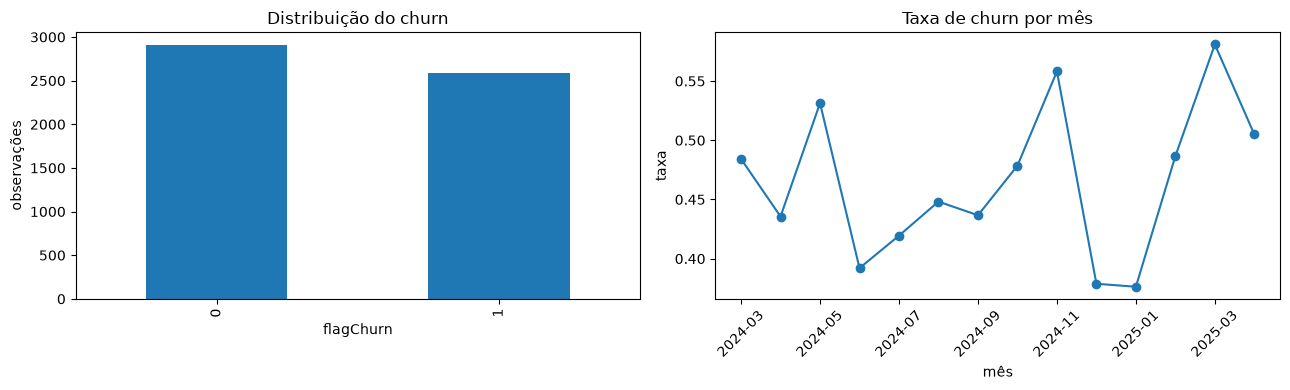

,correlacao_absoluta
qtdeDiasD14,0.485517
qtdeDiasD7,0.472538
qtdeDiasD28,0.459174
qtdeDiasUltimaTransacao,0.436425
propAvgQtdeDias,0.339503
qtdePontosPosD28,0.338672
qtdePontosPosD14,0.323644
qtdSkuDistintos,0.317395
qtdeDias,0.301866
qtdePontosPosD7,0.301831


In [3]:
print('Tipos de dados:')
display(df.dtypes.to_frame('dtype'))
print('Valores ausentes por coluna:')
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame('missing'))
print(f'Duplicidades completas: {df.duplicated().sum()}')
print('Distribuição do alvo:')
display(df['flagChurn'].value_counts(normalize=True).rename('proporcao').to_frame())

monthly_rate = df.assign(month=df['dtRef'].dt.to_period('M').astype(str)).groupby('month')['flagChurn'].agg(['count', 'mean'])
monthly_rate = monthly_rate.rename(columns={'count': 'observacoes', 'mean': 'taxa_churn'})
display(monthly_rate)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df['flagChurn'].value_counts().sort_index().plot.bar(ax=axes[0], title='Distribuição do churn', xlabel='flagChurn', ylabel='observações')
monthly_rate['taxa_churn'].plot(marker='o', ax=axes[1], title='Taxa de churn por mês', xlabel='mês', ylabel='taxa')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

numeric_columns = df.select_dtypes(include='number').columns.drop('flagChurn')
correlations = df[numeric_columns.tolist() + ['flagChurn']].corr()['flagChurn'].drop('flagChurn').abs().sort_values(ascending=False)
display(correlations.head(10).to_frame('correlacao_absoluta'))

## M — Modify

`idUsuario` é identificador e `dtRef` é usado somente para a separação temporal. As demais colunas são numéricas e entram no pipeline, que imputa valores pela mediana e padroniza os dados para a regressão logística.

In [4]:
target = 'flagChurn'
excluded_columns = ['idUsuario', 'dtRef', target]
feature_columns = [column for column in df.columns if column not in excluded_columns]
categorical_columns = [column for column in feature_columns if df[column].dtype == 'object']
numeric_feature_columns = [column for column in feature_columns if column not in categorical_columns]

transformers = [
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), numeric_feature_columns),
]
if categorical_columns:
    transformers.append((
        'categorical',
        Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ]),
        categorical_columns,
    ))
preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')

X_train, y_train = train[feature_columns], train[target]
X_validation, y_validation = validation[feature_columns], validation[target]
X_oot, y_oot = oot[feature_columns], oot[target]

assert set(X_train.columns).isdisjoint({'idUsuario', 'dtRef', 'flagChurn'})
print(f'Variáveis explicativas: {len(feature_columns)}')
print(f'Valores ausentes no treino: {int(X_train.isna().sum().sum())}')

Variáveis explicativas: 40
Valores ausentes no treino: 0


## M — Model

In [5]:
models = {
    'Regressão logística': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)),
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)),
    ]),
}

for model in models.values():
    model.fit(X_train, y_train)

print('Modelos treinados:', ', '.join(models))

Modelos treinados: Regressão logística, Random Forest


## A — Assess

accuracy  precision  recall      f1  roc_auc
modelo              amostra                                                
Random Forest       OOT          0.7855     0.7619  0.8366  0.7975   0.8410
                    validação    0.7761     0.7639  0.8893  0.8219   0.8386
Regressão logística OOT          0.7822     0.7636  0.8235  0.7925   0.8389
                    validação    0.7738     0.7667  0.8779  0.8185   0.8346

Melhor modelo na validação por ROC-AUC: Random Forest
Matriz de confusão OOT:


,previsto_0,previsto_1
real_0,110,40
real_1,25,128


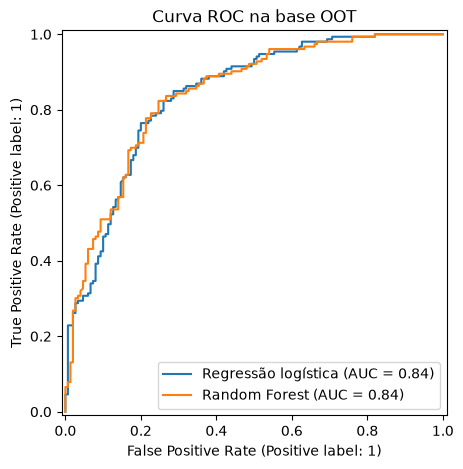

In [6]:
def assess(model, X, y, sample_name):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return {
        'amostra': sample_name,
        'accuracy': accuracy_score(y, predictions),
        'precision': precision_score(y, predictions, zero_division=0),
        'recall': recall_score(y, predictions, zero_division=0),
        'f1': f1_score(y, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y, probabilities),
    }

results = []
for model_name, model in models.items():
    results.append({**assess(model, X_validation, y_validation, 'validação'), 'modelo': model_name})
    results.append({**assess(model, X_oot, y_oot, 'OOT'), 'modelo': model_name})
results_df = pd.DataFrame(results).set_index(['modelo', 'amostra']).sort_index()
display(results_df.round(4))

best_model_name = results_df.xs('validação', level='amostra')['roc_auc'].idxmax()
best_model = models[best_model_name]
oot_predictions = best_model.predict(X_oot)
print(f'Melhor modelo na validação por ROC-AUC: {best_model_name}')
print('Matriz de confusão OOT:')
display(pd.DataFrame(
    confusion_matrix(y_oot, oot_predictions),
    index=['real_0', 'real_1'],
    columns=['previsto_0', 'previsto_1'],
))

fig, ax = plt.subplots(figsize=(7, 5))
for model_name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_oot, y_oot, name=model_name, ax=ax)
ax.set_title('Curva ROC na base OOT')
plt.show()


### Conclusão

A validação temporal compara os modelos em um período imediatamente posterior ao treino, enquanto a base OOT representa o último mês disponível. As métricas OOT devem ser interpretadas junto com o tamanho dessa amostra e com a possibilidade de mudança no comportamento dos usuários ao longo do tempo.